# Projeto 5 — Classificação de emoções com DistilBERT

UC de Redes Neurais. Comparamos encoder congelado, fine-tuning completo e fine-tuning otimizado por Optuna no dataset `dair-ai/emotion`.

Esta versão reutiliza os resultados salvos. Executar todas as células não repete treinamentos nem trials; somente recupera previsões por inferência quando necessário.


## Importações e reprodutibilidade

Seed 42. Avisos e erros permanecem visíveis; barras de progresso e logs informativos são desativados.


In [2]:
import hashlib
import json
import logging
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import optuna
from datasets import load_dataset
from datasets.utils.logging import disable_progress_bar
from huggingface_hub.utils import disable_progress_bars
from IPython.display import display
from transformers.utils import logging as hf_logging

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMENTE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

hf_logging.set_verbosity_warning()
hf_logging.disable_progress_bar()
disable_progress_bar()
disable_progress_bars()
optuna.logging.set_verbosity(optuna.logging.WARNING)


class FiltroCabecaInicial(logging.Filter):
    def filter(self, record):
        mensagem = re.sub(r"\x1b\[[0-9;]*m", "", record.getMessage())
        # Silencia somente o relatório esperado da troca da cabeça de classificação.
        if "LOAD REPORT" not in mensagem:
            return True
        entradas = re.findall(r"^\s*([\w.]+)\s*\|\s*(MISSING|UNEXPECTED)", mensagem, re.M)
        esperadas = {
            "pre_classifier.weight", "pre_classifier.bias", "classifier.weight", "classifier.bias",
            "vocab_transform.weight", "vocab_transform.bias", "vocab_projector.bias",
            "vocab_layer_norm.weight", "vocab_layer_norm.bias",
        }
        return not (
            entradas and all(chave in esperadas for chave, _ in entradas)
            and not any(erro in mensagem for erro in ("MISMATCH", "CONVERSION", "ERROR"))
        )


for handler in hf_logging.get_logger("transformers").handlers:
    handler.addFilter(FiltroCabecaInicial())


## Dataset

Usamos `load_dataset("dair-ai/emotion", "split")` e as divisões originais. Treino e validação orientam o ajuste; o teste é usado somente após a seleção dos modelos.


In [3]:
# O segundo argumento seleciona a configuração do dataset.
dataset = load_dataset("dair-ai/emotion", "split")

divisoes = {
    "train": "Treinamento",
    "validation": "Validação",
    "test": "Teste",
}

nomes_classes = dataset["train"].features["label"].names
tabela_classes = pd.DataFrame({
    "Rótulo": range(len(nomes_classes)),
    "Emoção": nomes_classes,
})
display(tabela_classes)

dados = {divisao: dataset[divisao].to_pandas() for divisao in divisoes}


,Rótulo,Emoção
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


## Quantidade e exemplos


In [4]:
quantidades = pd.DataFrame({
    "Divisão": list(divisoes.values()),
    "Exemplos": [len(dataset[divisao]) for divisao in divisoes],
})
display(quantidades)
print(f"Total de exemplos: {quantidades['Exemplos'].sum():,}")

exemplos = (
    dados["train"]
    .groupby("label", sort=True)
    .head(1)
    .sort_values("label")
    .copy()
)
exemplos["Emoção"] = exemplos["label"].map(dict(enumerate(nomes_classes)))
exemplos = exemplos.rename(columns={"text": "Texto", "label": "Rótulo"})

with pd.option_context("display.max_colwidth", None):
    display(exemplos[["Texto", "Rótulo", "Emoção"]].reset_index(drop=True))


,Divisão,Exemplos
0,Treinamento,16000
1,Validação,2000
2,Teste,2000


Total de exemplos: 20,000


,Texto,Rótulo,Emoção
0,i didnt feel humiliated,0,sadness
1,i have been with petronas for years i feel that petronas has performed well and made a huge profit,1,joy
2,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,2,love
3,im grabbing a minute to post i feel greedy wrong,3,anger
4,i feel as confused about life as a teenager or as jaded as a year old man,4,fear
5,ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny,5,surprise


## Distribuição das classes

Quantidades e percentuais nas divisões originais.


In [5]:
# Reindexar mantém todas as seis classes, mesmo se alguma tiver contagem zero.
contagens = pd.DataFrame({
    nome: dados[divisao]["label"].value_counts().reindex(
        range(len(nomes_classes)), fill_value=0
    )
    for divisao, nome in divisoes.items()
})
contagens.index = pd.Index(nomes_classes, name="Emoção")

percentuais = contagens.div(contagens.sum(axis=0), axis=1).mul(100)

print("Quantidade de exemplos por emoção:")
display(contagens)
print("Percentual por emoção dentro de cada divisão (%):")
display(percentuais.round(2))



Quantidade de exemplos por emoção:


,Treinamento,Validação,Teste
Emoção,,,
sadness,4666,550,581
joy,5362,704,695
love,1304,178,159
anger,2159,275,275
fear,1937,212,224
surprise,572,81,66


Percentual por emoção dentro de cada divisão (%):


,Treinamento,Validação,Teste
Emoção,,,
sadness,29.16,27.50,29.05
joy,33.51,35.20,34.75
love,8.15,8.90,7.95
anger,13.49,13.75,13.75
fear,12.11,10.60,11.20
surprise,3.58,4.05,3.30


## Valores ausentes e textos vazios

A verificação não altera os exemplos.


In [6]:
verificacoes = []

for divisao, nome in divisoes.items():
    df = dados[divisao]

    # O tipo string preserva ausentes; strip permite detectar só espaços.
    textos_vazios = df["text"].astype("string").str.strip().eq("").fillna(False)

    verificacoes.append({
        "Divisão": nome,
        "Textos ausentes": int(df["text"].isna().sum()),
        "Rótulos ausentes": int(df["label"].isna().sum()),
        "Textos vazios ou só espaços": int(textos_vazios.sum()),
    })

qualidade = pd.DataFrame(verificacoes).set_index("Divisão")
display(qualidade)

if qualidade.to_numpy().sum() == 0:
    print("Não foram encontrados textos vazios nem valores ausentes em text e label.")
else:
    print("Foram encontrados problemas. Revise a tabela antes de avançar no projeto.")


,Textos ausentes,Rótulos ausentes,Textos vazios ou só espaços
Divisão,,,
Treinamento,0,0,0
Validação,0,0,0
Teste,0,0,0


Não foram encontrados textos vazios nem valores ausentes em text e label.


## Tokenização

`distilbert-base-uncased`, truncamento em 128 tokens e padding dinâmico por lote. A ordem e os rótulos são preservados.


In [7]:
from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    AutoModelForSequenceClassification,
)

NOME_MODELO = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(NOME_MODELO)


def tokenizar_textos(exemplos):
    return tokenizer(
        exemplos["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )


# DatasetDict.map aplica a função às três divisões, sem criar novas divisões.
dataset_tokenizado = dataset.map(
    tokenizar_textos,
    batched=True,
    remove_columns=["text"],
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)


### Exemplo tokenizado


In [8]:
exemplo_original = dataset["train"][0]
exemplo_tokenizado = dataset_tokenizado["train"][0]

print("Texto original:", exemplo_original["text"])
print("Emoção:", nomes_classes[exemplo_original["label"]])
print("Tokens:", tokenizer.convert_ids_to_tokens(exemplo_tokenizado["input_ids"]))
print("input_ids:", exemplo_tokenizado["input_ids"])
print("attention_mask:", exemplo_tokenizado["attention_mask"])
print("Rótulo preservado:", exemplo_tokenizado["label"])

resumo_tokenizacao = []

assert set(dataset_tokenizado) == set(divisoes)

for divisao, nome in divisoes.items():
    original = dataset[divisao]
    tokenizado = dataset_tokenizado[divisao]

    assert len(tokenizado) == len(original), f"Quantidade alterada em {nome}"
    assert list(tokenizado["label"]) == list(original["label"]), (
        f"Rótulos ou ordem alterados em {nome}"
    )
    assert {"input_ids", "attention_mask", "label"}.issubset(tokenizado.column_names)

    comprimentos = [len(ids) for ids in tokenizado["input_ids"]]
    assert all(0 < tamanho <= MAX_LENGTH for tamanho in comprimentos)
    assert all(
        len(ids) == len(mascara) and all(valor == 1 for valor in mascara)
        for ids, mascara in zip(tokenizado["input_ids"], tokenizado["attention_mask"])
    ), f"Máscara inconsistente ou padding antecipado em {nome}"

    resumo_tokenizacao.append({
        "Divisão": nome,
        "Exemplos": len(tokenizado),
        "Menor sequência": min(comprimentos),
        "Maior sequência": max(comprimentos),
        "Rótulos preservados": True,
    })

display(pd.DataFrame(resumo_tokenizacao))

amostras = [dataset_tokenizado["train"][i] for i in range(3)]
lote_exemplo = data_collator(amostras)
assert lote_exemplo["input_ids"].shape[1] == max(
    len(amostra["input_ids"]) for amostra in amostras
)
assert lote_exemplo["labels"].tolist() == [amostra["label"] for amostra in amostras]
print("Formato dos tensores no lote:")
for campo, tensor in lote_exemplo.items():
    print(f"{campo}: {tuple(tensor.shape)} — {tensor.dtype}")

print("As três divisões foram tokenizadas e verificadas.")


Texto original: i didnt feel humiliated
Emoção: sadness
Tokens: ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]']
input_ids: [101, 1045, 2134, 2102, 2514, 26608, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1]
Rótulo preservado: 0


,Divisão,Exemplos,Menor sequência,Maior sequência,Rótulos preservados
0,Treinamento,16000,4,87,True
1,Validação,2000,4,69,True
2,Teste,2000,5,66,True


Formato dos tensores no lote:
input_ids: (3, 23) — torch.int64
token_type_ids: (3, 23) — torch.int64
attention_mask: (3, 23) — torch.int64
labels: (3,) — torch.int64
As três divisões foram tokenizadas e verificadas.


## DistilBERT

Transformer pré-treinado com cabeça de seis emoções. Os nomes das classes seguem a ordem original do dataset.


In [9]:
assert nomes_classes == ["sadness", "joy", "love", "anger", "fear", "surprise"]
id2label = dict(enumerate(nomes_classes))
label2id = {emocao: indice for indice, emocao in id2label.items()}
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

configuracao_modelo = json.loads(
    Path("results/baseline/melhor_modelo/config.json").read_text(encoding="utf-8")
)
parametros_modelo = json.loads(
    Path("results/baseline/parametros_modelo.json").read_text(encoding="utf-8")
)
display(pd.DataFrame([{
    "Checkpoint original": NOME_MODELO,
    "Arquitetura": configuracao_modelo["architectures"][0],
    "Classes": len(nomes_classes),
    "Parâmetros": parametros_modelo["totais"],
}]))


,Checkpoint original,Arquitetura,Classes,Parâmetros
0,distilbert-base-uncased,DistilBertForSequenceClassification,6,66958086


## Experimentos

Encoder congelado e baseline: AdamW, learning rate 2e-5, batch size 16, weight decay 0.01 e cinco épocas. O Optuna usa TPE com seed 42 e 15 trials de até cinco épocas, pruning após três épocas e early stopping com paciência 2. O melhor checkpoint é escolhido pelo Macro F1 de validação.


In [10]:
import gc
import inspect
import json
import math
import shutil
import tempfile
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import optuna
from optuna.trial import TrialState
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support,
)
from transformers import (
    Trainer, TrainingArguments, TrainerCallback, EarlyStoppingCallback, set_seed,
)

RAIZ_RESULTADOS = Path("results")
RAIZ_RESULTADOS.mkdir(exist_ok=True)
ROTULOS = list(range(len(nomes_classes)))
HIPERPARAMETROS_FIXOS = {
    "modelo": NOME_MODELO, "learning_rate": 2e-5, "batch_size": 16,
    "epocas": 5, "weight_decay": 0.01, "max_length": MAX_LENGTH,
    "seed": 42, "otimizador": "AdamW", "scheduler": "constant",
    "warmup_ratio": 0.0,
}
assert NOME_MODELO == "distilbert-base-uncased" and MAX_LENGTH == 128
assert SEMENTE == 42

# Libera o modelo demonstrativo: cada experimento carrega pesos originais novos.
if "modelo" in globals():
    del modelo
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


def salvar_json(caminho, conteudo):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    caminho.write_text(
        json.dumps(conteudo, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


def preservar_resultados(pasta):
    pasta = Path(pasta)
    arquivo_hp = pasta / "hiperparametros.json"
    if not arquivo_hp.exists():
        return
    hp_anterior = json.loads(arquivo_hp.read_text(encoding="utf-8"))
    if pasta.name == "baseline" and hp_anterior.get("epocas") == 3:
        destino = RAIZ_RESULTADOS / "baseline_3epocas"
        if destino.exists():
            # Não sobrescreve um arquivo histórico já preservado.
            return
    else:
        identificador = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        destino = RAIZ_RESULTADOS / "historico" / f"{pasta.name}_{identificador}"
    shutil.copytree(pasta, destino)


def criar_modelo_experimento(congelado=False):
    set_seed(SEMENTE)
    novo_modelo = AutoModelForSequenceClassification.from_pretrained(
        NOME_MODELO, num_labels=len(nomes_classes),
        id2label=id2label, label2id=label2id,
    )
    if congelado:
        # Inclui embeddings e todas as camadas Transformer no congelamento.
        for parametro in novo_modelo.distilbert.parameters():
            parametro.requires_grad = False
        assert not any(p.requires_grad for p in novo_modelo.distilbert.parameters())
        assert all(p.requires_grad for p in novo_modelo.pre_classifier.parameters())
        assert all(p.requires_grad for p in novo_modelo.classifier.parameters())
    return novo_modelo


def metricas_durante_treino(predicao):
    logits = predicao.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    previstas = np.argmax(logits, axis=-1)
    return {
        "accuracy": float(accuracy_score(predicao.label_ids, previstas)),
        "f1_macro": float(f1_score(
            predicao.label_ids, previstas, labels=ROTULOS,
            average="macro", zero_division=0,
        )),
    }


def criar_trainer(modelo_atual, hp, pasta_checkpoint, callbacks=None):
    # Calcula warmup_steps: também funciona em versões sem warmup_ratio.
    passos_epoca = math.ceil(len(dataset_tokenizado["train"]) / hp["batch_size"])
    warmup_steps = int(passos_epoca * hp["epocas"] * hp.get("warmup_ratio", 0.0))
    parametros = {
        "output_dir": str(pasta_checkpoint),
        "learning_rate": hp["learning_rate"],
        "per_device_train_batch_size": hp["batch_size"],
        "per_device_eval_batch_size": hp["batch_size"],
        "num_train_epochs": hp["epocas"],
        "weight_decay": hp["weight_decay"],
        "optim": "adamw_torch", "lr_scheduler_type": hp["scheduler"],
        "warmup_steps": warmup_steps, "gradient_accumulation_steps": 1,
        "logging_strategy": "epoch", "save_strategy": "epoch",
        "save_total_limit": 1, "load_best_model_at_end": True,
        "metric_for_best_model": "f1_macro", "greater_is_better": True,
        "seed": SEMENTE, "data_seed": SEMENTE, "full_determinism": True,
        "dataloader_num_workers": 0, "fp16": False, "bf16": False,
        "report_to": "none", "disable_tqdm": True, "log_level": "warning",
    }
    assinatura = inspect.signature(TrainingArguments.__init__).parameters
    estrategia = "eval_strategy" if "eval_strategy" in assinatura else "evaluation_strategy"
    parametros[estrategia] = "epoch"
    argumentos = TrainingArguments(**parametros)
    configuracao = {
        "model": modelo_atual, "args": argumentos,
        "train_dataset": dataset_tokenizado["train"],
        "eval_dataset": dataset_tokenizado["validation"],
        "data_collator": data_collator,
        "compute_metrics": metricas_durante_treino,
        "callbacks": callbacks or [],
    }
    assinatura_trainer = inspect.signature(Trainer.__init__).parameters
    processador = "processing_class" if "processing_class" in assinatura_trainer else "tokenizer"
    configuracao[processador] = tokenizer
    trainer = Trainer(**configuracao)
    # Mantém DefaultFlowCallback e o histórico interno das métricas.
    from transformers.trainer_callback import PrinterCallback
    trainer.remove_callback(PrinterCallback)
    return trainer


## Funções de avaliação e apresentação

Relatórios completos ficam nos arquivos. O notebook mostra resumos, históricos e gráficos de loss e Macro F1.


In [11]:
def avaliar_e_salvar(trainer, divisao, pasta):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    predicao = trainer.predict(dataset_tokenizado[divisao], metric_key_prefix=divisao)
    logits = predicao.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    reais = predicao.label_ids
    previstas = np.argmax(logits, axis=-1)
    metricas = {
        "divisao": divisao,
        "loss": float(predicao.metrics[f"{divisao}_loss"]),
        "accuracy": float(accuracy_score(reais, previstas)),
    }
    for media in ("macro", "weighted"):
        precisao, recall, f1, _ = precision_recall_fscore_support(
            reais, previstas, labels=ROTULOS, average=media, zero_division=0,
        )
        metricas.update({
            f"precision_{media}": float(precisao),
            f"recall_{media}": float(recall), f"f1_{media}": float(f1),
        })
    salvar_json(pasta / ("metricas_validacao.json" if divisao == "validation" else "metricas_teste.json"), metricas)
    relatorio = classification_report(
        reais, previstas, labels=ROTULOS, target_names=nomes_classes,
        zero_division=0, output_dict=True,
    )
    relatorio_texto = classification_report(
        reais, previstas, labels=ROTULOS, target_names=nomes_classes,
        zero_division=0, digits=4,
    )
    salvar_json(pasta / "relatorio_classificacao.json", relatorio)
    (pasta / "relatorio_classificacao.txt").write_text(relatorio_texto, encoding="utf-8")
    pd.DataFrame(relatorio).T.to_csv(pasta / "relatorio_classificacao.csv")
    matriz = confusion_matrix(reais, previstas, labels=ROTULOS)
    pd.DataFrame(matriz, index=nomes_classes, columns=nomes_classes).to_csv(
        pasta / "matriz_confusao.csv", index_label="Emoção real",
    )
    return metricas


def salvar_historico(historico, pasta):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    salvar_json(pasta / "historico_treinamento.json", historico)
    df = pd.DataFrame(historico)
    df.to_csv(pasta / "historico_treinamento.csv", index=False)
    if "eval_f1_macro" not in df:
        return
    validacao = df.loc[df["eval_f1_macro"].notna(),
                       ["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
    treino = df.loc[df["loss"].notna(), ["epoch", "loss"]]
    epocas = treino.merge(validacao, on="epoch", how="outer")
    epocas.to_csv(pasta / "historico_epocas.csv", index=False)
    return epocas


NOMES_MODELOS = {"frozen": "Encoder Congelado", "baseline": "Baseline", "optuna": "Optuna"}
PASTA_FINAL = RAIZ_RESULTADOS / "finalizacao"
PASTA_FINAL.mkdir(exist_ok=True)


def ler_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))


def guardar_tabela(tabela, nome):
    caminho = PASTA_FINAL / nome
    # Não sobrescreve resultados de uma finalização anterior.
    if not caminho.exists():
        tabela.to_csv(caminho, index=False)


def plotar_historico(historico, nome, pasta):
    fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
    eixos[0].plot(historico["epoch"], historico["loss"], "o-", label="Treino")
    eixos[0].plot(historico["epoch"], historico["eval_loss"], "o-", label="Validação")
    eixos[0].set(title=f"{nome} — Loss", xlabel="Época", ylabel="Loss")
    eixos[0].legend()
    eixos[1].plot(historico["epoch"], historico["eval_f1_macro"], "o-")
    eixos[1].set(title=f"{nome} — Macro F1 de validação", xlabel="Época", ylabel="Macro F1", ylim=(0, 1))
    fig.tight_layout()
    caminho = PASTA_FINAL / f"historico_{pasta}.png"
    if not caminho.exists():
        fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)


def apresentar_modelo(pasta):
    raiz = RAIZ_RESULTADOS / pasta
    nome = NOMES_MODELOS[pasta]
    selecao = ler_json(raiz / "selecao_melhor_modelo.json")
    tempo = ler_json(raiz / "tempo_treinamento.json")
    metricas = ler_json(raiz / "metricas_validacao.json")
    display(pd.DataFrame([{
        "Modelo": nome, "Divisão": "Validação",
        "Melhor época": int(selecao["epoca_selecionada"]),
        "Tempo (s)": round(tempo["segundos"], 2),
        "Accuracy": metricas["accuracy"], "F1 Macro": metricas["f1_macro"],
    }]).round(4))
    historico = pd.read_csv(raiz / "historico_epocas.csv")
    colunas = ["epoch", "loss", "eval_loss", "eval_f1_macro"]
    display(historico[colunas].rename(columns={
        "epoch": "Época", "loss": "Loss treino",
        "eval_loss": "Loss validação", "eval_f1_macro": "F1 Macro validação",
    }).round(4))
    plotar_historico(historico, nome, pasta)


## Treinamento

A implementação é mantida para documentar o procedimento; as células seguintes apenas apresentam os resultados já salvos.


In [12]:
def treinar_experimento(nome, hp, congelado=False, trial=None, early_stopping=False):
    pasta = (
        RAIZ_RESULTADOS / "optuna" / "trials" / f"trial_{trial.number:03d}"
        if trial is not None else RAIZ_RESULTADOS / nome
    )
    if trial is None:
        preservar_resultados(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    hp = {**hp, "encoder_congelado": congelado,
          "early_stopping_patience": 2 if early_stopping else None}
    salvar_json(pasta / "hiperparametros.json", hp)
    modelo_atual = None
    trainer = None
    inicio = perf_counter()
    historico = []
    estado = "FAIL"
    try:
        modelo_atual = criar_modelo_experimento(congelado)
        contagem = {
            "totais": sum(p.numel() for p in modelo_atual.parameters()),
            "treinaveis": sum(p.numel() for p in modelo_atual.parameters() if p.requires_grad),
        }
        salvar_json(pasta / "parametros_modelo.json", contagem)
        callbacks = []
        if early_stopping:
            callbacks.append(EarlyStoppingCallback(early_stopping_patience=2))
        if trial is not None:
            callbacks.append(RelatarTrialCallback(trial, pasta))
        with tempfile.TemporaryDirectory(prefix="checkpoints_", dir=pasta) as temporaria:
            trainer = criar_trainer(modelo_atual, hp, temporaria, callbacks)
            (pasta / "argumentos_treinamento.json").write_text(
                trainer.args.to_json_string(), encoding="utf-8",
            )
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            inicio = perf_counter()
            trainer.train()
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            segundos = perf_counter() - inicio
            historico = list(trainer.state.log_history)
            avaliacoes = [r for r in historico if "eval_f1_macro" in r]
            melhor = max(avaliacoes, key=lambda r: r["eval_f1_macro"])
            selecao = {
                "criterio": "Macro F1 na validação",
                "f1_macro": float(melhor["eval_f1_macro"]),
                "epoca_selecionada": float(melhor["epoch"]),
                "epocas_executadas": float(trainer.state.epoch),
            }
            salvar_json(pasta / "selecao_melhor_modelo.json", selecao)
            salvar_json(pasta / "tempo_treinamento.json", {"segundos": segundos})
            salvar_historico(historico, pasta)
            metricas = avaliar_e_salvar(trainer, "validation", pasta)
            if trial is None:
                destino_modelo = pasta / "melhor_modelo"
                trainer.save_model(str(destino_modelo))
                tokenizer.save_pretrained(str(destino_modelo))
            else:
                trial.set_user_attr("epoca_selecionada", selecao["epoca_selecionada"])
                trial.set_user_attr("metricas_validacao", metricas)
            salvar_json(pasta / "ambiente.json", {
                "bibliotecas": {n: version(n) for n in (
                    "torch", "transformers", "datasets", "accelerate", "optuna", "scikit-learn",
                )},
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            })
            estado = "COMPLETE"
            if trial is None:
                apresentar_modelo(nome)
            return {**selecao, "metricas": metricas, "tempo_segundos": segundos}
    except optuna.TrialPruned:
        estado = "PRUNED"
        raise
    finally:
        duracao_total = perf_counter() - inicio
        # Também preserva o histórico de trials podados ou que falharam.
        if trainer is not None and estado != "COMPLETE":
            salvar_historico(list(trainer.state.log_history), pasta)
        salvar_json(pasta / "estado_execucao.json", {
            "estado": estado, "duracao_total_segundos": duracao_total,
        })
        if trial is not None:
            trial.set_user_attr("duracao_total_segundos", duracao_total)
        # Accelerate também pode manter referências; o Trainer sai do escopo aqui.
        if trainer is not None:
            trainer.accelerator.free_memory()
        trainer = None
        modelo_atual = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


## Baseline — fine-tuning completo


,Modelo,Divisão,Melhor época,Tempo (s),Accuracy,F1 Macro
0,Baseline,Validação,4,350.83,0.9385,0.9153


,Época,Loss treino,Loss validação,F1 Macro validação
0,1.0,0.4684,0.2050,0.9015
1,2.0,0.1541,0.1711,0.9087
2,3.0,0.1227,0.1803,0.9140
3,4.0,0.0989,0.1960,0.9153
4,5.0,0.0769,0.2884,0.9022


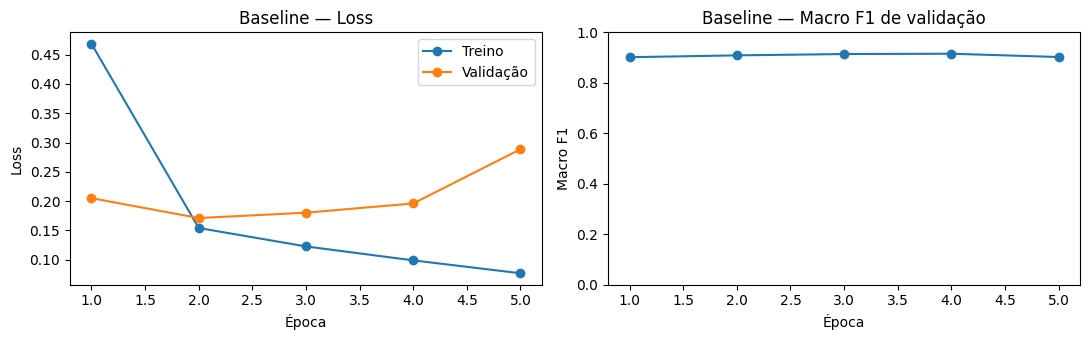

In [13]:
apresentar_modelo("baseline")


## Encoder congelado

Somente `pre_classifier` e `classifier` foram treinadas; embeddings e encoder permaneceram congelados.


,Modelo,Divisão,Melhor época,Tempo (s),Accuracy,F1 Macro
0,Encoder Congelado,Validação,5,114.05,0.546,0.2975


,Época,Loss treino,Loss validação,F1 Macro validação
0,1.0,1.5260,1.4433,0.2028
1,2.0,1.4003,1.3555,0.2071
2,3.0,1.3385,1.3107,0.2156
3,4.0,1.3013,1.2900,0.2468
4,5.0,1.2725,1.2510,0.2975


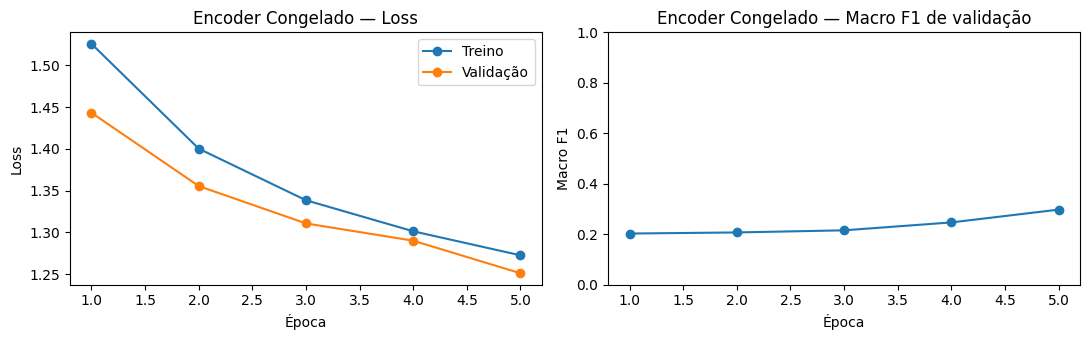

In [14]:
apresentar_modelo("frozen")


## Optuna — 15 trials

Busca de learning rate entre 1e-5 e 5e-5 (log), batch size 16 ou 32, weight decay e warmup ratio entre 0 e 0.1. Objetivo: maior Macro F1 na validação. Scheduler constante com warmup; checkpoint, pruning e early stopping usam apenas validação. O SQLite original é preservado.


In [15]:
PASTA_OPTUNA = RAIZ_RESULTADOS / "optuna"
PASTA_OPTUNA.mkdir(exist_ok=True)
TOTAL_TRIALS = 15

def carregar_estudo():
    return optuna.create_study(
        study_name="distilbert_emotion_5epocas_v1",
        storage="sqlite:///" + (PASTA_OPTUNA / "estudo.sqlite3").resolve().as_posix(),
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEMENTE),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=5, n_warmup_steps=3, interval_steps=1, n_min_trials=3,
        ),
        load_if_exists=True,
    )



class RelatarTrialCallback(TrainerCallback):
    def __init__(self, trial, pasta):
        self.trial = trial
        self.pasta = pasta
        self.melhor_f1 = -1.0

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        epoca = int(round(state.epoch))
        f1 = float(metrics["eval_f1_macro"])
        if f1 > self.melhor_f1:
            self.melhor_f1 = f1
            self.trial.set_user_attr("epoca_selecionada", epoca)
        self.trial.report(self.melhor_f1, step=epoca)
        self.trial.set_user_attr("melhor_f1_validacao", self.melhor_f1)
        # Salva por época para preservar progresso mesmo em uma interrupção.
        salvar_historico(list(state.log_history), self.pasta)
        if self.trial.should_prune():
            raise optuna.TrialPruned(f"Trial podado após a época {epoca}")


def objetivo_optuna(trial):
    hp = {
        **HIPERPARAMETROS_FIXOS,
        "learning_rate": trial.suggest_float("learning_rate", 1e-5, 5e-5, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.1),
        "scheduler": "constant_with_warmup",
        "epocas": 5,
    }
    resultado = treinar_experimento(
        "optuna_trial", hp, trial=trial, early_stopping=True,
    )
    return resultado["f1_macro"]


def exportar_trials():
    linhas = []
    for trial in estudo.trials:
        linhas.append({
            "trial": trial.number, "estado": trial.state.name,
            "f1_macro": trial.value,
            "duracao_segundos": (
                trial.duration.total_seconds() if trial.duration is not None else None
            ),
            **trial.params,
            "epoca_selecionada": trial.user_attrs.get("epoca_selecionada"),
        })
    colunas = [
        "trial", "estado", "f1_macro", "duracao_segundos",
        "learning_rate", "batch_size", "weight_decay", "warmup_ratio",
        "epoca_selecionada",
    ]
    tabela = pd.DataFrame(linhas, columns=colunas)
    tabela.to_csv(PASTA_OPTUNA / "trials.csv", index=False)
    salvar_json(PASTA_OPTUNA / "trials.json", linhas)
    return tabela


def apresentar_resultados_optuna():
    tabela = pd.read_csv(PASTA_OPTUNA / "trials.csv")
    colunas = {
        "trial": "Trial", "estado": "Estado", "f1_macro": "Macro F1 validação",
        "duracao_segundos": "Duração (s)", "learning_rate": "Learning rate",
        "batch_size": "Batch size", "weight_decay": "Weight decay",
        "warmup_ratio": "Warmup ratio", "epoca_selecionada": "Melhor época",
    }
    with pd.option_context("display.max_columns", None, "display.max_rows", None):
        display(tabela.rename(columns=colunas).round(6))
    melhor = ler_json(PASTA_OPTUNA / "resumo_melhor_trial.json")
    print(f"Melhor trial: {melhor['trial']} | Macro F1 de validação: "
          f"{melhor['f1_macro_validacao']:.6f}")
    display(pd.DataFrame(
        melhor["hiperparametros"].items(), columns=["Hiperparâmetro", "Valor"],
    ).style.format({"Valor": "{:.6g}"}))
    return tabela


def executar_busca_optuna():
    global estudo
    estudo = carregar_estudo()
    # RUNNING após queda do processo não é retomado por dentro do treinamento.
    # Exige intervenção explícita, evitando alterar um trial ainda em execução.
    pendentes = [t.number for t in estudo.trials if t.state == TrialState.RUNNING]
    if pendentes:
        raise RuntimeError(
            f"Trials RUNNING: {pendentes}. Se o processo anterior terminou, "
            "marque-os como FAIL com estudo.tell(numero, state=TrialState.FAIL)."
        )
    terminados = sum(t.state.is_finished() for t in estudo.trials)
    restantes = max(0, TOTAL_TRIALS - terminados)
    try:
        if restantes:
            estudo.optimize(
                objetivo_optuna, n_trials=restantes, n_jobs=1, gc_after_trial=True,
                catch=(torch.OutOfMemoryError,),
                callbacks=[lambda estudo_atual, trial: exportar_trials()],
            )
    finally:
        # Inclui estados e duração mesmo se a busca for interrompida.
        apresentar_resultados_optuna()


### Resultados da busca

Tentativas podadas também contam no orçamento de 15 trials.


In [16]:
tabela_trials = apresentar_resultados_optuna()


,Trial,Estado,Macro F1 validação,Duração (s),Learning rate,Batch size,Weight decay,Warmup ratio,Melhor época
0,0,COMPLETE,0.920638,367.899891,0.000018,16,0.059866,0.015602,4.0
1,1,COMPLETE,0.914666,289.025259,0.000013,32,0.060112,0.070807,3.0
2,2,COMPLETE,0.915029,357.738359,0.000010,16,0.021234,0.018182,4.0
3,3,COMPLETE,0.915113,289.065495,0.000013,32,0.043195,0.029123,3.0
4,4,COMPLETE,0.918656,282.519418,0.000027,32,0.036636,0.045607,4.0
5,5,PRUNED,0.913309,168.783815,0.000035,32,0.059241,0.004645,3.0
6,6,COMPLETE,0.917247,368.850416,0.000027,16,0.094889,0.096563,4.0
7,7,PRUNED,0.906607,211.671047,0.000037,16,0.068423,0.044015,2.0
8,8,PRUNED,0.913036,208.115990,0.000012,16,0.090932,0.025878,3.0
9,9,PRUNED,0.914143,156.687729,0.000029,32,0.054671,0.018485,3.0


Melhor trial: 0 | Macro F1 de validação: 0.920638


,Hiperparâmetro,Valor
0,learning_rate,1.82723e-05
1,batch_size,16
2,weight_decay,0.0598658
3,warmup_ratio,0.0156019


## Optuna — modelo final

O modelo final partiu dos pesos originais e utilizou os hiperparâmetros do melhor trial, com seleção do checkpoint pela validação.


,Modelo,Divisão,Melhor época,Tempo (s),Accuracy,F1 Macro
0,Optuna,Validação,4,315.56,0.941,0.9206


,Época,Loss treino,Loss validação,F1 Macro validação
0,1.0,0.5344,0.2044,0.8967
1,2.0,0.1617,0.1661,0.9164
2,3.0,0.1216,0.1645,0.9149
3,4.0,0.0974,0.2022,0.9206
4,5.0,0.0773,0.2424,0.9097


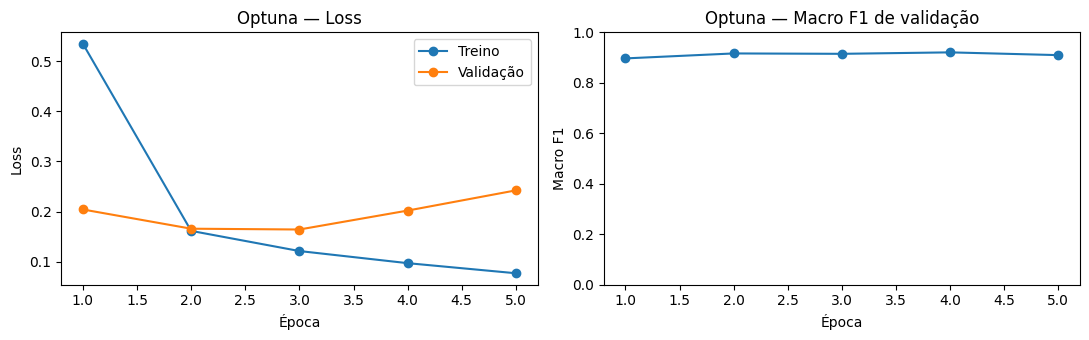

In [17]:
apresentar_modelo("optuna")


## Matrizes de confusão — teste

As previsões individuais são reutilizadas ou recuperadas dos checkpoints finais, na ordem original do teste. Nenhum peso é atualizado.


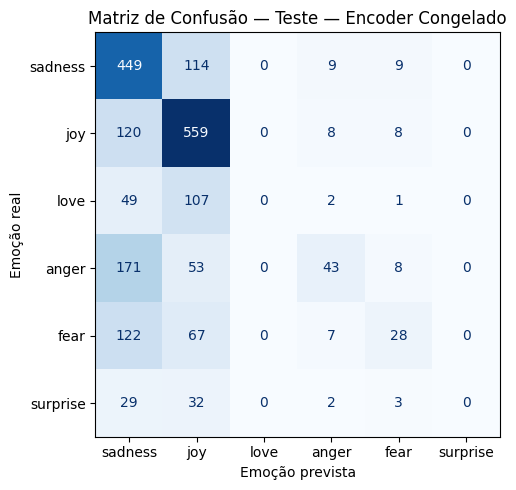

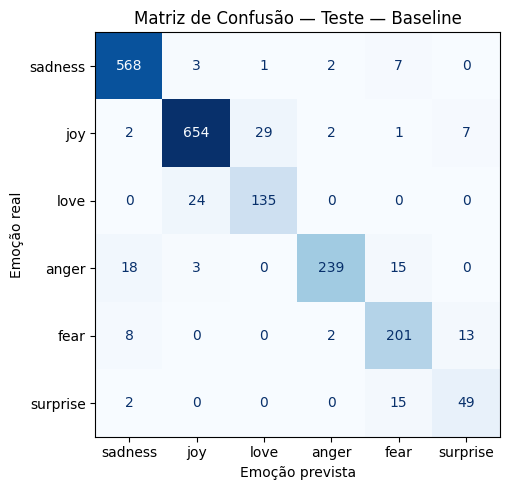

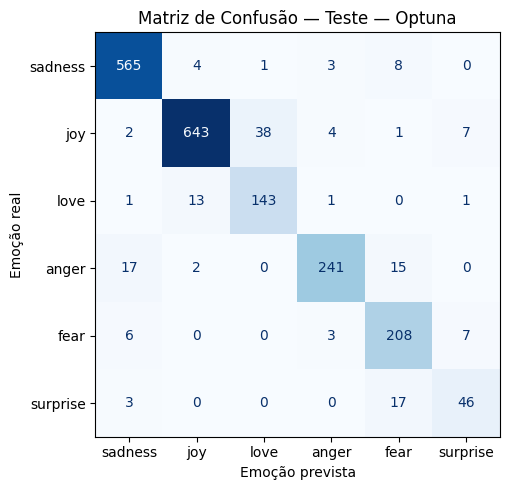

In [18]:
from torch.utils.data import DataLoader


def hash_arquivo(caminho):
    resumo = hashlib.sha256()
    with Path(caminho).open("rb") as arquivo:
        for trecho in iter(lambda: arquivo.read(1024 * 1024), b""):
            resumo.update(trecho)
    return resumo.hexdigest()


def previsoes_teste(pasta):
    raiz = RAIZ_RESULTADOS / pasta
    estado = ler_json(raiz / "estado_execucao.json")
    assert estado["estado"] == "COMPLETE", f"Modelo incompleto: {pasta}"
    assert (RAIZ_RESULTADOS / "optuna/melhor_trial.json").exists()
    textos = list(dataset["test"]["text"])
    reais = np.asarray(dataset["test"]["label"])
    caminho = raiz / "teste/previsoes_teste.csv"
    caminho_meta = raiz / "teste/previsoes_teste_meta.json"
    assinatura = hash_arquivo(raiz / "melhor_modelo/model.safetensors")

    if caminho.exists():
        previsoes = pd.read_csv(caminho, keep_default_na=False)
        assert caminho_meta.exists(), "Previsões sem identificação do checkpoint."
        assert ler_json(caminho_meta)["sha256_modelo"] == assinatura
    else:
        modelo_final = None
        try:
            tokenizer_final = AutoTokenizer.from_pretrained(
                raiz / "melhor_modelo", local_files_only=True,
            )
            collator_final = DataCollatorWithPadding(tokenizer_final, return_tensors="pt")
            # Confere que a mesma tokenização foi utilizada pelos três modelos.
            exemplo = tokenizer_final(textos[0], truncation=True, max_length=MAX_LENGTH)
            assert exemplo["input_ids"] == dataset_tokenizado["test"][0]["input_ids"]
            modelo_final = AutoModelForSequenceClassification.from_pretrained(
                raiz / "melhor_modelo", local_files_only=True,
            ).to(dispositivo)
            assert modelo_final.config.id2label == id2label
            modelo_final.eval()
            lotes = DataLoader(
                dataset_tokenizado["test"], batch_size=16,
                shuffle=False, collate_fn=collator_final,
            )
            previstas = []
            with torch.inference_mode():
                for lote in lotes:
                    rotulos_lote = lote.pop("labels")
                    entradas = {chave: valor.to(dispositivo) for chave, valor in lote.items()}
                    logits = modelo_final(**entradas).logits
                    previstas.extend(logits.argmax(dim=-1).cpu().tolist())
            previsoes = pd.DataFrame({
                "indice": range(len(textos)), "texto": textos,
                "rotulo_real": reais, "rotulo_previsto": previstas,
            })
        finally:
            modelo_final = None
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    assert previsoes["indice"].tolist() == list(range(len(textos)))
    assert previsoes["texto"].tolist() == textos
    assert np.array_equal(previsoes["rotulo_real"].to_numpy(), reais)
    assert previsoes["rotulo_previsto"].isin(ROTULOS).all()
    matriz = confusion_matrix(reais, previsoes["rotulo_previsto"], labels=ROTULOS)
    matriz_salva = pd.read_csv(raiz / "teste/matriz_confusao.csv", index_col=0)
    assert matriz_salva.index.tolist() == nomes_classes
    assert matriz_salva.columns.tolist() == nomes_classes
    assert np.array_equal(matriz, matriz_salva.to_numpy()), (
        f"Previsões de {pasta} divergem da matriz de teste salva; resultados originais preservados."
    )
    if not caminho.exists():
        previsoes.to_csv(caminho, index=False)
        salvar_json(caminho_meta, {
            "sha256_modelo": assinatura, "checkpoint": str(raiz / "melhor_modelo"),
            "dataset": "dair-ai/emotion", "configuracao": "split",
            "divisao": "test", "max_length": MAX_LENGTH, "exemplos": len(previsoes),
        })
    return previsoes


predicoes = {pasta: previsoes_teste(pasta) for pasta in NOMES_MODELOS}
for pasta, nome in NOMES_MODELOS.items():
    previsoes = predicoes[pasta]
    matriz = confusion_matrix(
        previsoes["rotulo_real"], previsoes["rotulo_previsto"], labels=ROTULOS,
    )
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ConfusionMatrixDisplay(matriz, display_labels=nomes_classes).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False,
    )
    ax.set(title=f"Matriz de Confusão — Teste — {nome}",
           xlabel="Emoção prevista", ylabel="Emoção real")
    fig.tight_layout()
    caminho = PASTA_FINAL / f"matriz_confusao_teste_{pasta}.png"
    if not caminho.exists():
        fig.savefig(caminho, dpi=150)
    plt.show()
    plt.close(fig)


## Comparação dos modelos

Validação e teste são apresentados separadamente; o teste não orienta novos ajustes.


In [19]:
COLUNAS_METRICAS = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision Macro", "precision_weighted": "Precision Weighted",
    "recall_macro": "Recall Macro", "recall_weighted": "Recall Weighted",
    "f1_macro": "F1 Macro", "f1_weighted": "F1 Weighted",
}


def tabela_comparativa(divisao):
    linhas = []
    for pasta, nome in NOMES_MODELOS.items():
        raiz = RAIZ_RESULTADOS / pasta
        arquivo = raiz / (
            "metricas_validacao.json" if divisao == "validation" else "teste/metricas_teste.json"
        )
        metricas = ler_json(arquivo)
        linhas.append({
            "Modelo": nome, "Divisão": "Validação" if divisao == "validation" else "Teste",
            **{rotulo: metricas[chave] for chave, rotulo in COLUNAS_METRICAS.items()},
            "Tempo (s)": ler_json(raiz / "tempo_treinamento.json")["segundos"],
        })
    tabela = pd.DataFrame(linhas)
    guardar_tabela(tabela, f"comparacao_{divisao}.csv")
    with pd.option_context("display.max_columns", None):
        display(tabela.round(4))
    return tabela


comparacao_validacao = tabela_comparativa("validation")
comparacao_teste = tabela_comparativa("test")


,Modelo,Divisão,Accuracy,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,F1 Macro,F1 Weighted,Tempo (s)
0,Encoder Congelado,Validação,0.5460,0.5161,0.5625,0.3221,0.5460,0.2975,0.4713,114.0485
1,Baseline,Validação,0.9385,0.9182,0.9398,0.9139,0.9385,0.9153,0.9385,350.8312
2,Optuna,Validação,0.9410,0.9143,0.9439,0.9293,0.9410,0.9206,0.9415,315.5618


,Modelo,Divisão,Accuracy,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,F1 Macro,F1 Weighted,Tempo (s)
0,Encoder Congelado,Teste,0.5395,0.3624,0.4855,0.3097,0.5395,0.2876,0.4668,114.0485
1,Baseline,Teste,0.9230,0.8751,0.9250,0.8794,0.9230,0.8765,0.9234,350.8312
2,Optuna,Teste,0.9230,0.8757,0.9262,0.8832,0.9230,0.8778,0.9235,315.5618


## McNemar — teste

Comparamos acertos e erros nas mesmas amostras. Usamos o teste exato bilateral, α = 0,05 e correção de Holm para os três pares. McNemar não testa diretamente diferenças de F1; as tabelas 2×2 ficam salvas em `results/finalizacao/mcnemar_contingencias.json`.


In [20]:
from scipy.stats import binomtest

ALPHA = 0.05
PARES = [("frozen", "baseline"), ("frozen", "optuna"), ("baseline", "optuna")]


def ajuste_holm(p_valores):
    p_valores = np.asarray(p_valores, dtype=float)
    ordem = np.argsort(p_valores)
    corrigidos = np.empty(len(p_valores))
    corrigidos[ordem] = np.minimum(
        1.0, np.maximum.accumulate((len(p_valores) - np.arange(len(p_valores))) * p_valores[ordem]),
    )
    return corrigidos


linhas = []
contingencias = {}
for modelo_a, modelo_b in PARES:
    a, b = predicoes[modelo_a], predicoes[modelo_b]
    assert a[["indice", "texto", "rotulo_real"]].equals(b[["indice", "texto", "rotulo_real"]])
    acerto_a = a["rotulo_previsto"].to_numpy() == a["rotulo_real"].to_numpy()
    acerto_b = b["rotulo_previsto"].to_numpy() == b["rotulo_real"].to_numpy()
    ambos_acertam = int((acerto_a & acerto_b).sum())
    apenas_a = int((acerto_a & ~acerto_b).sum())
    apenas_b = int((~acerto_a & acerto_b).sum())
    ambos_erram = int((~acerto_a & ~acerto_b).sum())
    tabela_2x2 = [[ambos_acertam, apenas_a], [apenas_b, ambos_erram]]
    comparacao = f"{NOMES_MODELOS[modelo_a]} × {NOMES_MODELOS[modelo_b]}"
    contingencias[comparacao] = {
        "linhas": ["A acerta", "A erra"], "colunas": ["B acerta", "B erra"],
        "tabela": tabela_2x2,
    }
    # McNemar exato equivale ao teste binomial bilateral dos pares discordantes.
    discordantes = apenas_a + apenas_b
    p_valor = binomtest(apenas_a, discordantes, p=0.5).pvalue if discordantes else 1.0
    linhas.append({
        "Comparação (A × B)": comparacao,
        "A acerta / B erra": apenas_a, "A erra / B acerta": apenas_b,
        "Método": "Exato (binomial)", "p original": float(p_valor),
    })

mcnemar_resultados = pd.DataFrame(linhas)
mcnemar_resultados["p Holm"] = ajuste_holm(mcnemar_resultados["p original"])
mcnemar_resultados["Significativo (α=0,05)"] = np.where(
    mcnemar_resultados["p Holm"] <= ALPHA, "Sim", "Não",
)
guardar_tabela(mcnemar_resultados, "mcnemar_teste.csv")
if not (PASTA_FINAL / "mcnemar_contingencias.json").exists():
    salvar_json(PASTA_FINAL / "mcnemar_contingencias.json", contingencias)
with pd.option_context("display.max_columns", None):
    display(mcnemar_resultados.style.format({"p original": "{:.4g}", "p Holm": "{:.4g}"}))


,Comparação (A × B),A acerta / B erra,A erra / B acerta,Método,p original,p Holm,"Significativo (α=0,05)"
0,Encoder Congelado × Baseline,43,810,Exato (binomial),2.129e-184,6.387e-184,Sim
1,Encoder Congelado × Optuna,53,820,Exato (binomial),1.186e-177,2.371e-177,Sim
2,Baseline × Optuna,25,25,Exato (binomial),1,1,Não


## Exemplos de previsões — teste

Cinco textos reais, priorizando divergências entre baseline e Optuna. A seleção é apenas ilustrativa e não altera os modelos.


In [21]:
reais = predicoes["baseline"]["rotulo_real"].to_numpy()
baseline = predicoes["baseline"]["rotulo_previsto"].to_numpy()
otimizado = predicoes["optuna"]["rotulo_previsto"].to_numpy()
frozen = predicoes["frozen"]["rotulo_previsto"].to_numpy()

selecionados = []
# Prioriza os dois sentidos de divergência entre baseline e Optuna.
for mascara in ((baseline == reais) & (otimizado != reais),
                (otimizado == reais) & (baseline != reais)):
    candidatos = np.flatnonzero(mascara)
    if candidatos.size:
        selecionados.append(int(candidatos[0]))
for mascara in (baseline != otimizado, (frozen != baseline) | (frozen != otimizado),
                np.ones(len(reais), dtype=bool)):
    for indice in np.flatnonzero(mascara):
        if int(indice) not in selecionados:
            selecionados.append(int(indice))
        if len(selecionados) == 5:
            break
    if len(selecionados) == 5:
        break

exemplos_teste = pd.DataFrame({
    "Texto": [dataset["test"][int(i)]["text"] for i in selecionados],
    "Emoção verdadeira": [nomes_classes[reais[i]] for i in selecionados],
    "Encoder Congelado": [nomes_classes[frozen[i]] for i in selecionados],
    "Baseline": [nomes_classes[baseline[i]] for i in selecionados],
    "Optuna": [nomes_classes[otimizado[i]] for i in selecionados],
})
guardar_tabela(exemplos_teste, "exemplos_previsoes_teste.csv")
with pd.option_context("display.max_colwidth", None):
    display(exemplos_teste)


,Texto,Emoção verdadeira,Encoder Congelado,Baseline,Optuna
0,i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepted into the masters program at the university of virginia,joy,sadness,joy,love
1,i felt anger when at the end of a telephone call,anger,sadness,fear,anger
2,i was feeling weird the other day and it went away about minutes after i took my metformin,fear,sadness,surprise,fear
3,i feel very mislead by someone that i really really thought i knew and liked very much so,love,sadness,love,anger
4,i was so uncomfortable and feeling weird feelings but wasn t sure if they were contractions since i never really felt contractions with jared until they jacked me up with pitocin,surprise,sadness,surprise,fear
